# Lab Khai phá dữ liệu - Câu 7: Nhận dạng chữ số viết tay (MNIST/digits)
**Trần Minh Tấn - 6451071071**

## Cell 1: Chuẩn bị các thư viện cần thiết

In [1]:
%matplotlib inline
import matplotlib
import matplotlib.pyplot as plt

from sklearn import datasets, tree, metrics
from sklearn.model_selection import train_test_split

HO_TEN = "Trần Minh Tấn"
MSSV   = "6451071071"

def info(cau=""):
    print("=" * 55)
    print(f"Họ tên : {HO_TEN}")
    print(f"MSSV   : {MSSV}")
    if cau:
        print(f"Nội dung: {cau}")
    print("=" * 55)

info("Chuẩn bị các thư viện cần thiết")

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Chuẩn bị các thư viện cần thiết


## Cell 2: Download dữ liệu có sẵn trong thư viện sklearn

In [2]:
info("Download dữ liệu có sẵn trong thư viện sklearn")

# The digits dataset
digits = datasets.load_digits()
print("Số ảnh:", len(digits.images), "| Kích thước mỗi ảnh:", digits.images[0].shape)

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Download dữ liệu có sẵn trong thư viện sklearn
Số ảnh: 1797 | Kích thước mỗi ảnh: (8, 8)


## Cell 3: Biểu diễn 4 mẫu dữ liệu huấn luyện tương ứng với 4 lớp 0, 1, 2, 3

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Biểu diễn 4 mẫu dữ liệu huấn luyện tương ứng với 4 lớp 0, 1, 2, 3


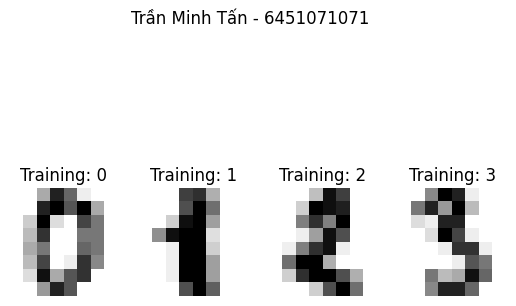

In [3]:
info("Biểu diễn 4 mẫu dữ liệu huấn luyện tương ứng với 4 lớp 0, 1, 2, 3")

# The data that we are interested in is made of 8x8 images of digits, let's
# have a look at the first 4 images, stored in the `images` attribute of the
# dataset.  If we were working from image files, we could load them using
# matplotlib.pyplot.imread.  Note that each image must have the same size. For these
# images, we know which digit they represent: it is given in the 'target' of
# the dataset.
_, axes = plt.subplots(1, 4)
images_and_labels = list(zip(digits.images, digits.target))
for ax, (image, label) in zip(axes, images_and_labels[:4]):
    ax.set_axis_off()
    ax.imshow(image, cmap=plt.cm.gray_r, interpolation='nearest')
    ax.set_title('Training: %i' % label)
plt.suptitle(f"{HO_TEN} - {MSSV}")
plt.show()

## Cell 4: Chuyển đổi mỗi đối tượng hình ảnh - ma trận 8x8 thành ma trận 1x64

In [4]:
info("Chuyển đổi ma trận 8x8 thành ma trận 1x64")

# To apply a classifier on this data, we need to flatten the image, to
# turn the data in a (samples, feature) matrix:
n_samples = len(digits.images)
data = digits.images.reshape((n_samples, -1))
print("Kích thước data:", data.shape)

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Chuyển đổi ma trận 8x8 thành ma trận 1x64
Kích thước data: (1797, 64)


## Cell 5: Sử dụng thuật toán cây ID3

In [5]:
info("Sử dụng thuật toán cây ID3")

# Create a classifier: a decision tree classifier
classifier = tree.DecisionTreeClassifier(criterion="entropy", random_state=33)
classifier

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Sử dụng thuật toán cây ID3


DecisionTreeClassifier(criterion='entropy', random_state=33)

## Cell 6: Chia dữ liệu thành hai phần: huấn luyện 80%, kiểm thử 20%

In [6]:
info("Chia dữ liệu: huấn luyện 80%, kiểm thử 20%")

# Split data into train and test subsets
X_train, X_test, y_train, y_test = train_test_split(
    data, digits.target, test_size=0.2, shuffle=False)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Chia dữ liệu: huấn luyện 80%, kiểm thử 20%
X_train: (1437, 64) | X_test: (360, 64)


## Cell 7: Tiến hành xây dựng cây ID3

In [7]:
info("Tiến hành xây dựng cây ID3")

# We learn the digits on the first part of the digits
classifier.fit(X_train, y_train)

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Tiến hành xây dựng cây ID3


DecisionTreeClassifier(criterion='entropy', random_state=33)

## Cell 8: Dự đoán nhãn dữ liệu cho tập kiểm thử

In [8]:
info("Dự đoán nhãn dữ liệu cho tập kiểm thử")

# Now predict the value of the digit on the second part:
predicted = classifier.predict(X_test)
print("Đã dự đoán", len(predicted), "mẫu")

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Dự đoán nhãn dữ liệu cho tập kiểm thử
Đã dự đoán 360 mẫu


## Cell 9: Biểu diễn một vài kết quả dự đoán

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Biểu diễn một vài kết quả dự đoán


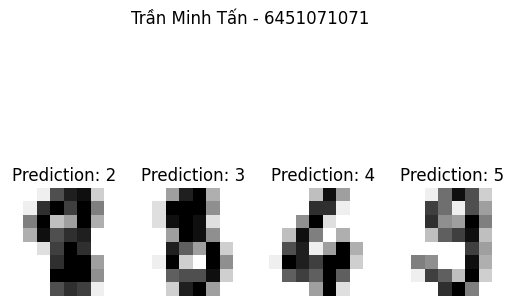

In [9]:
info("Biểu diễn một vài kết quả dự đoán")

_, axes = plt.subplots(1, 4)
images_and_predictions = list(zip(digits.images[n_samples // 2:], predicted))
for ax, (image, prediction) in zip(axes, images_and_predictions[:4]):
    ax.set_axis_off()
    ax.imshow(image, cmap=plt.cm.gray_r, interpolation='nearest')
    ax.set_title('Prediction: %i' % prediction)
plt.suptitle(f"{HO_TEN} - {MSSV}")
plt.show()

## Cell 10: Thông số đạt được của cây ID3 và ma trận nhầm lẫn

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Thông số đạt được của cây ID3 và ma trận nhầm lẫn
Classification report for classifier DecisionTreeClassifier(criterion='entropy', random_state=33):
              precision    recall  f1-score   support

           0       0.86      0.89      0.87        35
           1       0.72      0.64      0.68        36
           2       0.76      0.74      0.75        35
           3       0.69      0.59      0.64        37
           4       0.86      0.84      0.85        37
           5       0.80      0.95      0.86        37
           6       0.97      0.95      0.96        37
           7       0.78      0.86      0.82        36
           8       0.79      0.82      0.81        33
           9       0.72      0.70      0.71        37

    accuracy                           0.80       360
   macro avg       0.80      0.80      0.79       360
weighted avg       0.80      0.80      0.79       360


Confusion matrix:
[[31  0  0  0  1  0 

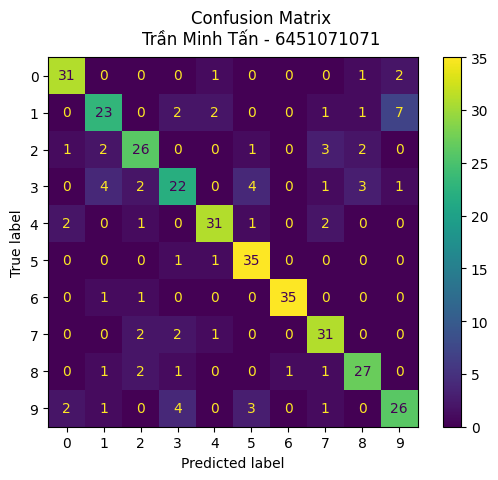

In [10]:
info("Thông số đạt được của cây ID3 và ma trận nhầm lẫn")

print("Classification report for classifier %s:\n%s\n"
      % (classifier, metrics.classification_report(y_test, predicted)))

# Lưu ý: metrics.plot_confusion_matrix đã bị xóa ở sklearn bản mới,
# thay bằng ConfusionMatrixDisplay.from_estimator (cùng chức năng)
disp = metrics.ConfusionMatrixDisplay.from_estimator(classifier, X_test, y_test)
disp.figure_.suptitle(f"Confusion Matrix\n{HO_TEN} - {MSSV}")
print("Confusion matrix:\n%s" % disp.confusion_matrix)
plt.show()

## Cell 11: Cài đặt thư viện pillow, import và tải ảnh chữ số viết tay từ Drive

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Cài đặt pillow, import và tải ảnh chữ số viết tay


Downloading...
From: https://drive.google.com/uc?id=1KU83z5OU2j69YBPI7uMPcLPSUxidd6Ia
To: /content/sample_2.jpg
100%|██████████| 52.0k/52.0k [00:00<00:00, 11.9MB/s]


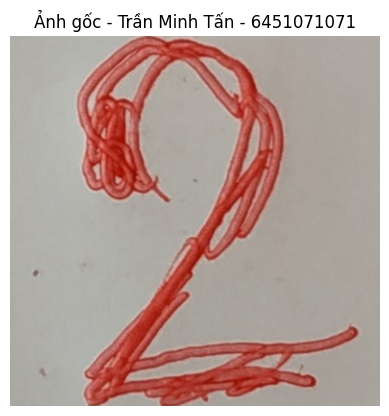

In [11]:
info("Cài đặt pillow, import và tải ảnh chữ số viết tay")

!pip install -q pillow gdown
from PIL import Image, ImageOps
import numpy as np
import gdown

IMG_ID = "1KU83z5OU2j69YBPI7uMPcLPSUxidd6Ia"   # ảnh chữ số viết tay
gdown.download(id=IMG_ID, output="sample_2.jpg", quiet=False)

# Xem ảnh gốc
plt.imshow(Image.open("sample_2.jpg"))
plt.axis("off")
plt.title(f"Ảnh gốc - {HO_TEN} - {MSSV}")
plt.show()

## Cell 12: Đọc hình vào phần mềm

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Đọc hình vào phần mềm


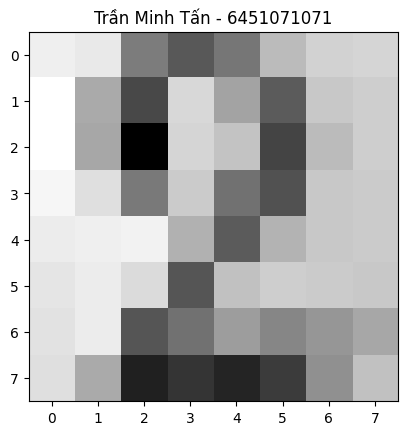

In [12]:
info("Đọc hình vào phần mềm")

#Open image
img = Image.open('sample_2.jpg').convert("L").resize((8,8))
#Invert image
img = ImageOps.invert(img)
#Convert to numpy array
im2arr = np.array(img)
#Show
plt.imshow(im2arr, cmap=plt.cm.gray_r, interpolation='nearest')
plt.title(f"{HO_TEN} - {MSSV}")
plt.show()

## Cell 13: Làm rõ nét bức ảnh (phân biệt giá trị đen, trắng)
Ngưỡng mặc định là 110. Nếu ảnh chụp khác điều kiện ánh sáng, sinh viên chỉnh biến `THRESHOLD`.

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Làm rõ nét bức ảnh bằng cách phân biệt giá trị đen, trắng
[[  0   0 155 155 155   0   0   0   0   0 155   0   0 155   0   0   0   0
  155   0   0 155   0   0   0   0 155   0 155 155   0   0   0   0   0   0
  155   0   0   0   0   0   0 155   0   0   0   0   0   0 155 155   0 155
    0   0   0   0 155 155 155 155   0   0]]


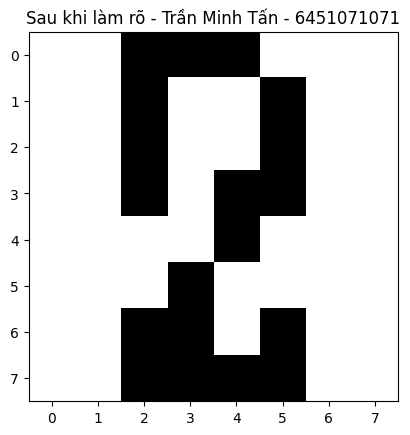

In [13]:
info("Làm rõ nét bức ảnh bằng cách phân biệt giá trị đen, trắng")

THRESHOLD = 110   # có thể điều chỉnh tùy điều kiện ảnh chụp

#Change from 2d array (8x8) to 1d array (1x64)
img1d = im2arr.reshape([1,64])
#normalize black & white image array
img1d[img1d > THRESHOLD - 1] = 155
img1d[img1d < THRESHOLD] = 0
print(img1d)

#After normalize
plt.imshow(im2arr, cmap=plt.cm.gray_r, interpolation='nearest')
plt.title(f"Sau khi làm rõ - {HO_TEN} - {MSSV}")
plt.show()

## Cell 14: Tiến hành nhận diện bằng cây ID3 và in ra kết quả

In [14]:
info("Tiến hành nhận diện bằng cây ID3 và in ra kết quả")

#Predict label of number
y_pred = classifier.predict(img1d)
print(y_pred)
print("Chữ số được nhận diện:", y_pred[0])

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Tiến hành nhận diện bằng cây ID3 và in ra kết quả
[2]
Chữ số được nhận diện: 2
